In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn kneed

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\user\AppData\Local\Python\pythoncore-3.15-64\python.exe -m pip install --upgrade pip


FIRST FIVE ROWS:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

DATASET SHAPE:
(100000, 9)

SAMPLE SIZE: 1000


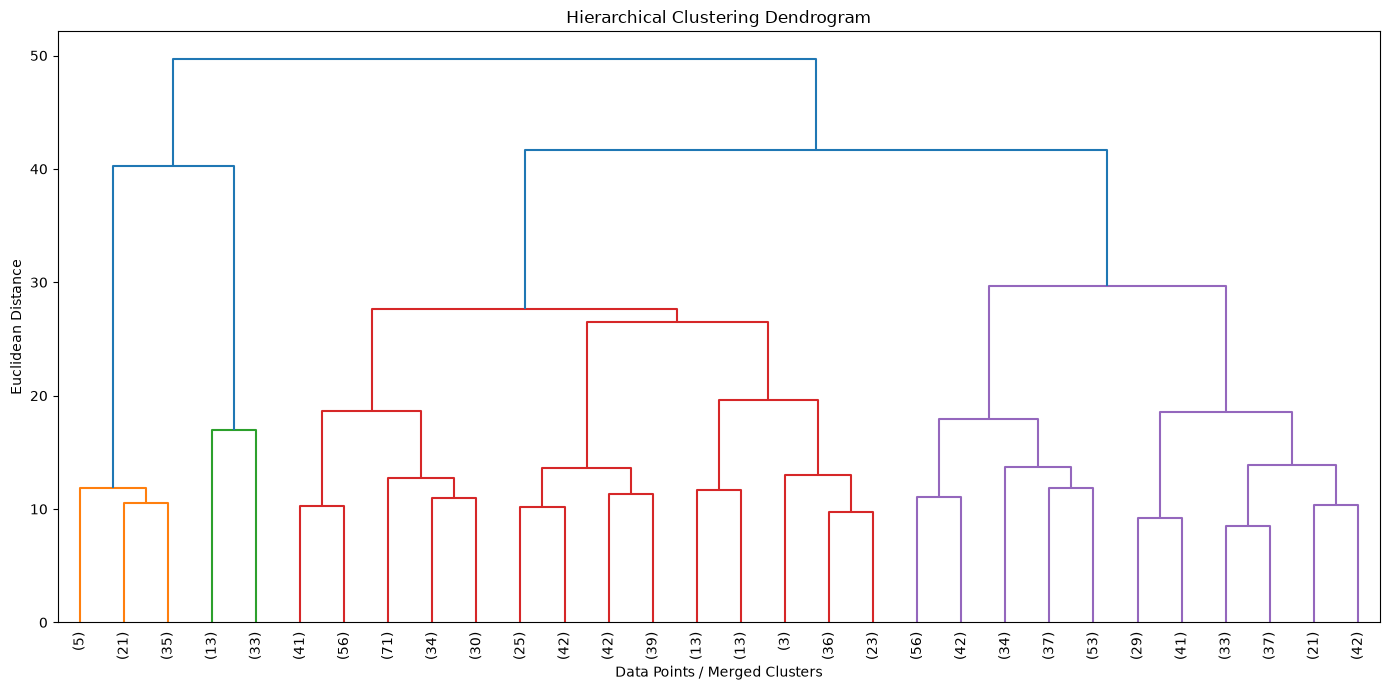


NUMBER OF CLUSTERS: 12

CLUSTER LABELS:
[1 1 2 6 5 6 4 1 4 6 5 6 2 1 1 0 1 0 0 8]

CLUSTER COUNTS:
Cluster
0     133
1     124
2     148
3      61
4      98
5      62
6     135
7      26
8      97
9      70
10     33
11     13
Name: count, dtype: int64


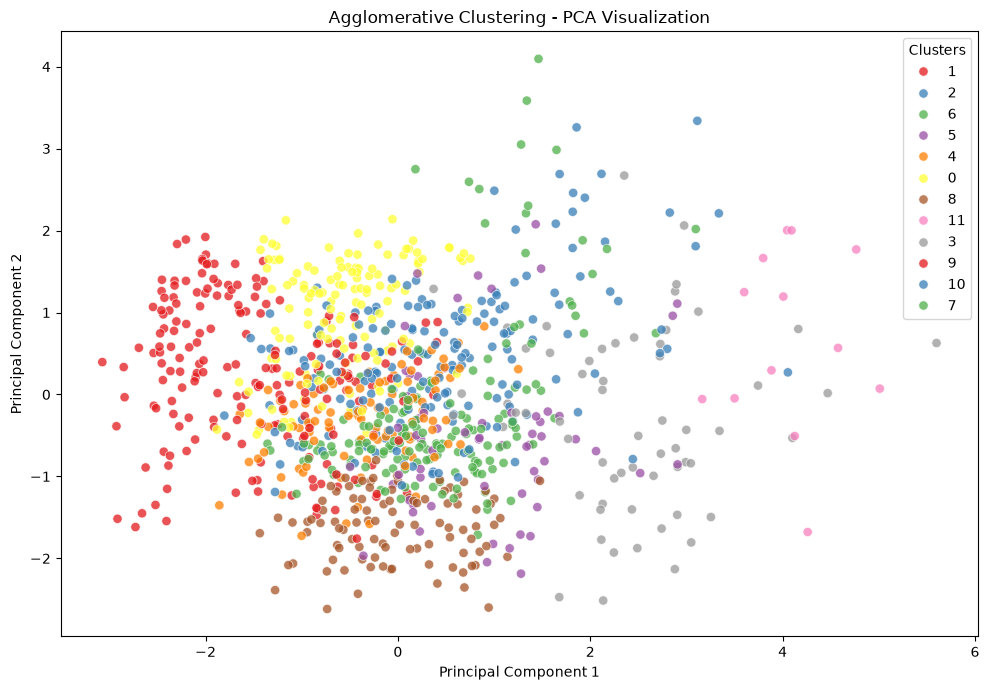


CLUSTER-WISE FEATURE AVERAGES:
         gender    age  hypertension  heart_disease  smoking_history    bmi  \
Cluster                                                                       
0          1.00  43.49           0.0            0.0             0.35  27.45   
1          0.00  20.88           0.0            0.0             0.29  23.85   
2          1.00  40.78           0.0            0.0             3.97  27.67   
3          0.39  59.31           1.0            0.0             2.93  32.54   
4          0.00  51.38           0.0            0.0             0.23  27.23   
5          0.15  40.79           0.0            0.0             2.74  41.62   
6          0.00  44.24           0.0            0.0             3.91  24.82   
7          0.50  57.42           0.0            0.0             2.85  32.94   
8          0.00  41.96           0.0            0.0             3.89  26.31   
9          1.00   7.56           0.0            0.0             0.03  20.79   
10         0.67  67.

In [4]:

# HIERARCHICAL CLUSTERING
# Dendrogram + Agglomerative Clustering

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# 2. Load dataset
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("FIRST FIVE ROWS:")
print(df.head())

print("\nDATASET SHAPE:")
print(df.shape)

# 3. Handle missing values
df = df.dropna().copy()

# 4. Encode categorical columns
df['gender'] = df['gender'].astype('category').cat.codes
df['smoking_history'] = df['smoking_history'].astype('category').cat.codes

# 5. Select features
# Remove target column because clustering is unsupervised
X = df.drop('diabetes', axis=1)

# 6. Select a sample to avoid MemoryError
sample_size = min(1000, len(X))

X_sample = X.sample(
    n=sample_size,
    random_state=42
)

print("\nSAMPLE SIZE:", len(X_sample))

# 7. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

# 8. Build dendrogram using Ward linkage
linked = linkage(X_scaled, method='ward')

# 9. Plot dendrogram
plt.figure(figsize=(14, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Merged Clusters")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

# 10. Determine number of clusters
# Change the distance after observing your dendrogram
distance_threshold = 15

cluster_labels = fcluster(
    linked,
    t=distance_threshold,
    criterion='distance'
)

number_of_clusters = len(np.unique(cluster_labels))

print("\nNUMBER OF CLUSTERS:", number_of_clusters)

# 11. Apply Agglomerative Clustering
model = AgglomerativeClustering(
    n_clusters=number_of_clusters,
    linkage='ward'
)

labels = model.fit_predict(X_scaled)

X_sample = X_sample.copy()
X_sample['Cluster'] = labels

print("\nCLUSTER LABELS:")
print(labels[:20])

# 12. Cluster counts
print("\nCLUSTER COUNTS:")
print(X_sample['Cluster'].value_counts().sort_index())

# 13. PCA for visualization
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    'PCA1': X_pca[:, 0],
    'PCA2': X_pca[:, 1],
    'Cluster': labels.astype(str)
})

# 14. Visualize clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=plot_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    s=45,
    alpha=0.75
)

plt.title("Agglomerative Clustering - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Clusters")
plt.tight_layout()
plt.show()

# 15. Cluster-wise feature averages
print("\nCLUSTER-WISE FEATURE AVERAGES:")
print(
    X_sample.groupby('Cluster')
    .mean(numeric_only=True)
    .round(2)
)

# 16. Final summary
print("\n========== FINAL SUMMARY ==========")
print("Algorithm: Hierarchical Clustering")
print("Method: Agglomerative Clustering")
print("Linkage: Ward")
print("Distance: Euclidean")
print("Number of Clusters:", number_of_clusters)
print("Total Records Used:", len(X_sample))

print(
    "PCA Variance Explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

print("\nHIERARCHICAL CLUSTERING COMPLETED SUCCESSFULLY!")
